## **Notebook 3: Feature Extraction & Clustering**
Goal: Extract deep features from malignant images, cluster them to discover subtypes, validate the clusters, and interpret them biologically.

In [ ]:
# --- IMPORTS ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import joblib # For saving the scaler and K-Means model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model

# --- 1. SET GLOBAL PARAMETERS ---
DATA_DIR = "/content/drive/MyDrive/BreastCancerProject/data/processed"
MODEL_DIR = "/content/drive/MyDrive/BreastCancerProject/models"
RESULTS_DIR = "/content/drive/MyDrive/BreastCancerProject/results/figures"
TABLES_DIR = "/content/results/drive/MyDrive/BreastCancerProject/figures"

SEED = 42
np.random.seed(SEED)

In [ ]:
import os

In [ ]:
# --- 2. LOAD MALIGNANT-ONLY DATA ---
print("Loading malignant-only data for clustering...")
X_cluster_train = np.load(os.path.join(DATA_DIR, 'X_cluster_train.npy'))
X_cluster_val = np.load(os.path.join(DATA_DIR, 'X_cluster_val.npy'))
y_cluster_train = np.load(os.path.join(DATA_DIR, 'y_cluster_train.npy'))
y_cluster_val = np.load(os.path.join(DATA_DIR, 'y_cluster_val.npy'))

print(f"Cluster Train set: {X_cluster_train.shape}")
print(f"Cluster Validation set: {X_cluster_val.shape}")

Loading malignant-only data for clustering...
Cluster Train set: (210, 224, 224, 3)
Cluster Validation set: (90, 224, 224, 3)


In [ ]:
# --- 3. INITIALIZE FEATURE EXTRACTOR (ResNet50) ---
print("\nInitializing ResNet50 feature extractor...")
base_model = ResNet50(weights='imagenet',
                      include_top=False, # Remove the classification head
                      pooling='avg')     # Apply Global Average Pooling to the last conv layer
# This creates a model that takes an image and outputs a 2048-dimensional vector
feature_extractor = Model(inputs=base_model.input, outputs=base_model.output)
feature_extractor.trainable = False # Freeze all weights
print("✔️ Feature extractor ready. Summary:")
feature_extractor.summary()


Initializing ResNet50 feature extractor...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✔️ Feature extractor ready. Summary:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, None,      │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, None,      │      9,472 │ conv1_pad[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, None,      │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, None,      │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, None,      │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, None,      │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, None,      │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, None,      │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, None,      │          0 │ conv2_block1_1_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, None,      │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, None,      │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, None,      │          0 │ conv2_block1_2_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, None,      │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, None,      │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, None,      │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, None,      │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# --- 4. EXTRACT FEATURES ---
def extract_features(images, feature_extractor_model, batch_size=16):
    """Extracts features from a batch of images using the pre-trained model."""
    # Preprocess images for ResNet50
    processed_imgs = preprocess_input(images.copy().astype('float32'))
    # Predict features
    features = feature_extractor_model.predict(processed_imgs, batch_size=batch_size, verbose=1)
    return features

print("\nExtracting features from training set...")
train_features = extract_features(X_cluster_train, feature_extractor)
print(f"Extracted training features shape: {train_features.shape}")

print("Extracting features from validation set...")
val_features = extract_features(X_cluster_val, feature_extractor)
print(f"Extracted validation features shape: {val_features.shape}")


Extracting features from training set...
14/14 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step
Extracted training features shape: (210, 2048)
Extracting features from validation set...
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step
Extracted validation features shape: (90, 2048)


In [ ]:
np.save(os.path.join(DATA_DIR, 'resnet50_train_features.npy'), train_features)
np.save(os.path.join(DATA_DIR, 'resnet50_val_features.npy'), val_features)
print("✔️ Features saved for future use.")

In [ ]:
# --- 5. SCALE FEATURES ---
print("\nScaling features...")
scaler = StandardScaler()
scaled_train_features = scaler.fit_transform(train_features)
scaled_val_features = scaler.transform(val_features) # Use the scaler fitted on the training data!

# Save the scaler for use in the UI later
joblib.dump(scaler, os.path.join(MODEL_DIR, 'feature_scaler.pkl'))
print("✔️ Features scaled and scaler saved.")


Scaling features...
✔️ Features scaled and scaler saved.


In [ ]:
# --- 6. DETERMINE OPTIMAL NUMBER OF CLUSTERS (K) ---
print("\n" + "="*60)
print("FINDING THE OPTIMAL NUMBER OF CLUSTERS (K)")
print("="*60)

k_range = range(2, 6) # Test K from 2 to 5
silhouette_scores = []
ch_scores = [] # Calinski-Harabasz (Higher is better)
db_scores = [] # Davies-Bouldin (Lower is better)

print("K\tSilhouette\tC-H Score\tD-B Score")
print("-" * 40)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    cluster_labels = kmeans.fit_predict(scaled_train_features)

    # Calculate metrics
    sil_score = silhouette_score(scaled_train_features, cluster_labels)
    ch_score = calinski_harabasz_score(scaled_train_features, cluster_labels)
    db_score = davies_bouldin_score(scaled_train_features, cluster_labels)

    silhouette_scores.append(sil_score)
    ch_scores.append(ch_score)
    db_scores.append(db_score)

    print(f"{k}\t{sil_score:.4f}\t\t{ch_score:.2f}\t\t{db_score:.4f}")


FINDING THE OPTIMAL NUMBER OF CLUSTERS (K)
K	Silhouette	C-H Score	D-B Score
----------------------------------------
2	0.0658		14.39		3.5339
3	0.0339		11.31		3.9463
4	0.0317		9.24		3.3768
5	0.0130		7.99		3.8403


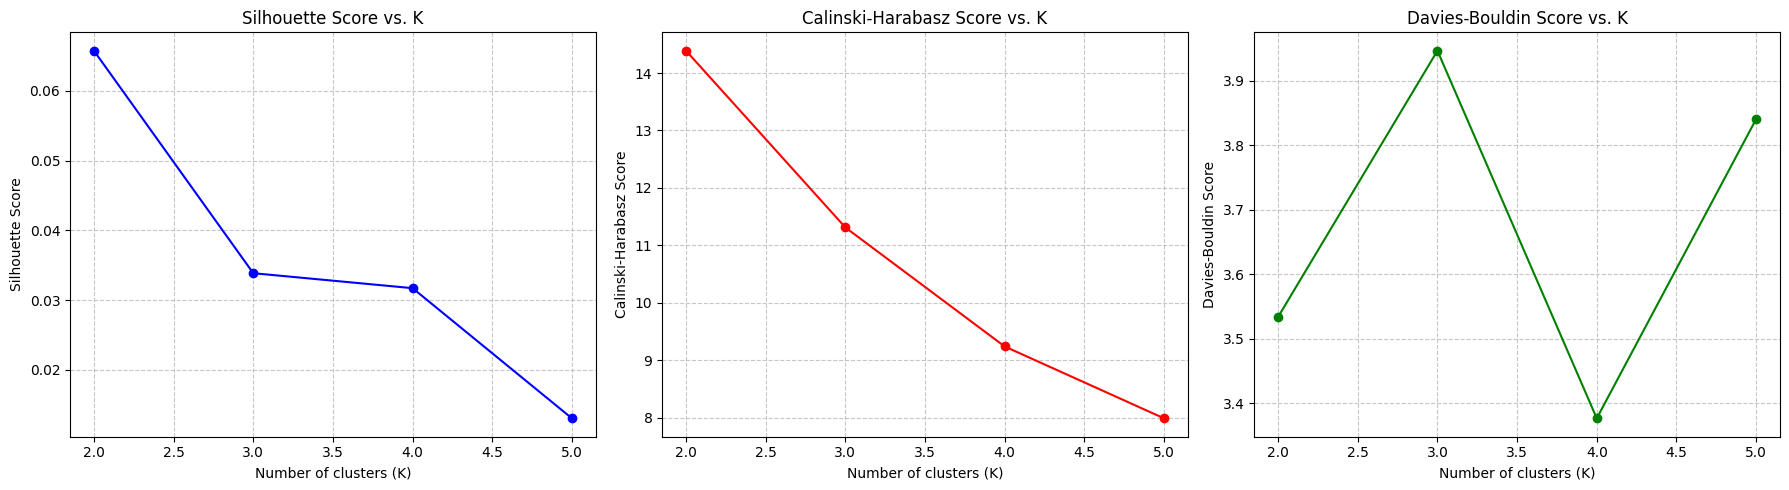

In [ ]:
# Plot the results
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Silhouette Score
ax1.plot(k_range, silhouette_scores, 'bo-')
ax1.set_xlabel('Number of clusters (K)')
ax1.set_ylabel('Silhouette Score')
ax1.set_title('Silhouette Score vs. K')
ax1.grid(True, linestyle='--', alpha=0.7)

# Calinski-Harabasz Score
ax2.plot(k_range, ch_scores, 'ro-')
ax2.set_xlabel('Number of clusters (K)')
ax2.set_ylabel('Calinski-Harabasz Score')
ax2.set_title('Calinski-Harabasz Score vs. K')
ax2.grid(True, linestyle='--', alpha=0.7)

# Davies-Bouldin Score
ax3.plot(k_range, db_scores, 'go-')
ax3.set_xlabel('Number of clusters (K)')
ax3.set_ylabel('Davies-Bouldin Score')
ax3.set_title('Davies-Bouldin Score vs. K')
ax3.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'cluster_metrics_vs_k.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# --- 7. CHOOSE K AND TRAIN FINAL K-MEANS MODEL ---
# Based on metrics we choose K=2.
chosen_k = 2
print(f"\nBased on metrics and biological rationale, choosing K = {chosen_k}")

print(f"\nTraining final K-Means model with K={chosen_k}...")
final_kmeans = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10)
train_cluster_labels = final_kmeans.fit_predict(scaled_train_features)

# Save the K-Means model for the UI
joblib.dump(final_kmeans, os.path.join(MODEL_DIR, 'kmeans_model.pkl'))
print("✔️ Final K-Means model trained and saved.")


Based on metrics and biological rationale, choosing K = 2

Training final K-Means model with K=2...
✔️ Final K-Means model trained and saved.


In [ ]:
# --- 8. VALIDATE CLUSTERS ON HELD-OUT SET ---
print("\n" + "="*60)
print("VALIDATING CLUSTERS ON HELD-OUT VALIDATION SET")
print("="*60)

# Predict clusters for the validation set
val_cluster_labels = final_kmeans.predict(scaled_val_features)

# Calculate validation metrics
val_sil_score = silhouette_score(scaled_val_features, val_cluster_labels)
val_ch_score = calinski_harabasz_score(scaled_val_features, val_cluster_labels)
val_db_score = davies_bouldin_score(scaled_val_features, val_cluster_labels)

print("--- Validation Set Metrics ---")
print(f"Silhouette Score: {val_sil_score:.4f}")
print(f"Calinski-Harabasz Score: {val_ch_score:.2f}")
print(f"Davies-Bouldin Score: {val_db_score:.4f}")

# Compare with training metrics
print("\n--- Comparison (Train vs Val) ---")
print(f"Silhouette: {silhouette_scores[chosen_k-2]:.4f} (Train) vs {val_sil_score:.4f} (Val)")
print(f"C-H Score: {ch_scores[chosen_k-2]:.2f} (Train) vs {val_ch_score:.2f} (Val)")
print(f"D-B Score: {db_scores[chosen_k-2]:.4f} (Train) vs {val_db_score:.4f} (Val)")

# A small drop is acceptable. A large drop indicates overfitting.


VALIDATING CLUSTERS ON HELD-OUT VALIDATION SET
--- Validation Set Metrics ---
Silhouette Score: 0.0451
Calinski-Harabasz Score: 5.84
Davies-Bouldin Score: 3.3519

--- Comparison (Train vs Val) ---
Silhouette: 0.0658 (Train) vs 0.0451 (Val)
C-H Score: 14.39 (Train) vs 5.84 (Val)
D-B Score: 3.5339 (Train) vs 3.3519 (Val)


In [ ]:
# --- 9. BIOLOGICAL INTERPRETATION: LINK CLUSTERS TO DIAGNOSTIC LABELS ---
print("\n" + "="*60)
print("BIOLOGICAL INTERPRETATION: Cluster vs. Diagnostic Label")
print("="*60)

# Create a DataFrame for analysis
cluster_analysis_df = pd.DataFrame({
    'Diagnostic_Label': y_cluster_train,
    'Cluster_Label': train_cluster_labels
})
# Map numeric labels to names for readability
diagnostic_map = {1: 'Benign', 2: 'InSitu', 3: 'Invasive'}
cluster_analysis_df['Diagnostic_Name'] = cluster_analysis_df['Diagnostic_Label'].map(diagnostic_map)

# Create a cross-tabulation
cross_tab = pd.crosstab(
    index=cluster_analysis_df['Cluster_Label'],
    columns=cluster_analysis_df['Diagnostic_Name'],
    margins=True,
    margins_name="Total"
)
print("\n📊 Cross-Tabulation: Cluster Assignment vs. Diagnostic Label")
print(cross_tab)

# Calculate percentages
cross_tab_pct = pd.crosstab(
    index=cluster_analysis_df['Cluster_Label'],
    columns=cluster_analysis_df['Diagnostic_Name'],
    normalize='index' # 'index' means row-wise percentage
).round(4) * 100
print("\n📊 Percentages (Row-wise):")
print(cross_tab_pct)

# Save the cross-tab results
cross_tab.to_csv(os.path.join(TABLES_DIR, '/cluster_diagnostic_crosstab.csv'))
cross_tab_pct.to_csv(os.path.join(TABLES_DIR, '/cluster_diagnostic_crosstab_pct.csv'))


BIOLOGICAL INTERPRETATION: Cluster vs. Diagnostic Label

📊 Cross-Tabulation: Cluster Assignment vs. Diagnostic Label
Diagnostic_Name  Benign  InSitu  Invasive  Total
Cluster_Label                                   
0                    49      60         6    115
1                    21      10        64     95
Total                70      70        70    210

📊 Percentages (Row-wise):
Diagnostic_Name  Benign  InSitu  Invasive
Cluster_Label                            
0                 42.61   52.17      5.22
1                 22.11   10.53     67.37



Generating t-SNE visualization...


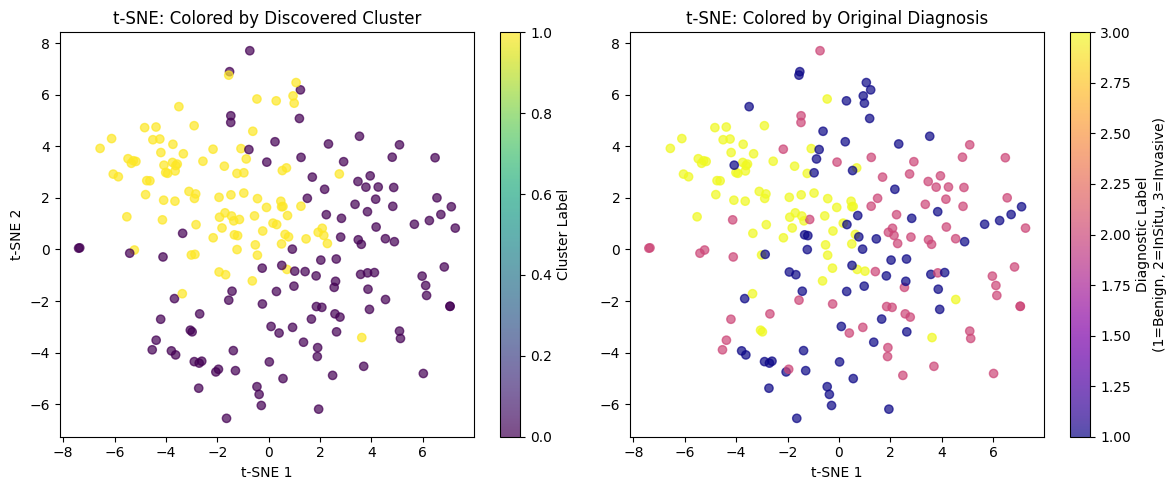

In [ ]:
# --- 10. VISUALIZE CLUSTERS (t-SNE) ---
print("\nGenerating t-SNE visualization...")
from sklearn.manifold import TSNE

# Use a subset of the training data for faster t-SNE computation
sample_size = min(500, len(scaled_train_features))
sample_indices = np.random.choice(len(scaled_train_features), sample_size, replace=False)
sampled_features = scaled_train_features[sample_indices]
sampled_labels = train_cluster_labels[sample_indices]
sampled_diagnostic = y_cluster_train[sample_indices]

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
tsne_results = tsne.fit_transform(sampled_features)

# Plot
plt.figure(figsize=(12, 5))

# Plot 1: Colored by Cluster
plt.subplot(1, 2, 1)
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=sampled_labels, cmap='viridis', alpha=0.7)
plt.colorbar(scatter, label='Cluster Label')
plt.title('t-SNE: Colored by Discovered Cluster')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')

# Plot 2: Colored by Diagnostic Label
plt.subplot(1, 2, 2)
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=sampled_diagnostic, cmap='plasma', alpha=0.7)
plt.colorbar(scatter, label='Diagnostic Label\n(1=Benign, 2=InSitu, 3=Invasive)')
plt.title('t-SNE: Colored by Original Diagnosis')
plt.xlabel('t-SNE 1')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'tsne_cluster_visualization.png'), dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# --- 11. SAVE FINAL CLUSTER LABELS FOR THE UI ---
# These are the labels for the training images, which we will use to characterize the clusters.
np.save(os.path.join(DATA_DIR, 'train_cluster_labels.npy'), train_cluster_labels)
print("✔️ Cluster labels for training set saved.")

print("\n" + "="*60)
print("NOTEBOOK 3 EXECUTION COMPLETE!")
print("="*60)
print("Summary of saved assets for the UI:")
print(f"  1. Feature Extractor: ResNet50 (built-in)")
print(f"  2. Scaler: {MODEL_DIR}/feature_scaler.pkl")
print(f"  3. K-Means Model: {MODEL_DIR}/kmeans_model.pkl")
print(f"  4. Cluster Labels: {DATA_DIR}/train_cluster_labels.npy")
print("\nNext step: Proceed to Notebook 4 for Cluster Characterization and Phytochemical Mapping.")

✔️ Cluster labels for training set saved.

NOTEBOOK 3 EXECUTION COMPLETE!
Summary of saved assets for the UI:
  1. Feature Extractor: ResNet50 (built-in)
  2. Scaler: /content/drive/MyDrive/BreastCancerProject/models/feature_scaler.pkl
  3. K-Means Model: /content/drive/MyDrive/BreastCancerProject/models/kmeans_model.pkl
  4. Cluster Labels: /content/drive/MyDrive/BreastCancerProject/data/processed/train_cluster_labels.npy

Next step: Proceed to Notebook 4 for Cluster Characterization and Phytochemical Mapping.
